# Dataset Description

**Source:** Lending Club loan data (US peer-to-peer lender), loans issued June 2007 to December 2011. All amounts are in US dollars.

| Item | Value |
|---|---|
| Rows in raw file | 39,717 loans (one row per loan) |
| Columns in raw file | 111 (54 are completely empty) |
| Loans used for modelling | 38,577 (loans with a known outcome) |
| Fully Paid (good, 0) | 32,950 |
| Charged Off (default, 1) | 5,627 |
| Default rate | 14.6% |
| Excluded | 1,140 loans still "Current" (outcome not yet known) |

**Target variable:** `bad` = 1 if the loan was Charged Off, 0 if Fully Paid.

**Columns not used as model inputs**
- **Repayment columns** (`total_pymnt`, `total_rec_prncp`, `recoveries`, `out_prncp` and similar): only known after the loan is issued, so using them would cause data leakage.
- **Lending Club's own risk opinion** (`grade`, `sub_grade`, `int_rate`, `installment`): kept only as a benchmark (`bench_grade`, `bench_int_rate`), so the model does not copy their judgement.
- **Identifiers, free text and constant columns** (`id`, `member_id`, `url`, `emp_title`, `zip_code`, `policy_code`, etc.): no predictive use.

**Train/test split:** stratified 70/30 (random_state = 42). All fill values, caps and category groupings are calculated on train rows only.

# Variable Labels

| Variable | Label | Unit / Values |
|---|---|---|
| `bad` | Defaulted (target) | 1 = Charged Off, 0 = Fully Paid |
| `loan_amnt` | Loan amount requested | $ |
| `term_months` | Loan term | 36 or 60 months |
| `annual_inc_capped` | Annual income (capped at 99th percentile) | $ |
| `annual_inc_log` | Annual income, log scale | log($) |
| `dti` | Debt-to-income ratio (monthly debt payments excluding mortgage and this loan, divided by monthly income) | % |
| `emp_length_years` | Years in current job | 0 to 10 (10 = 10 or more) |
| `credit_history_years` | Length of credit history at issue | years |
| `revol_bal_capped` | Revolving balance, e.g. credit cards (capped) | $ |
| `revol_util` | Revolving utilisation: share of available credit used | % (capped at 100) |
| `open_acc_capped` | Open credit accounts (capped) | count |
| `total_acc_capped` | Total credit accounts ever opened (capped) | count |
| `open_acc_share` | Share of accounts that are open | 0 to 1 |
| `pub_rec_capped` | Derogatory public records (capped at 2) | count |
| `delinq_2yrs_capped` | Late payments of 30+ days in last 2 years (capped at 3) | count |
| `inq_last_6mths_capped` | Credit enquiries in last 6 months (capped at 5) | count |
| `loan_to_income` | Loan amount / annual income | ratio |
| `revol_bal_to_income` | Revolving balance / annual income | ratio |
| `desc_words` | Words in the loan description | count |
| `desc_score` | Text risk score from the description (out-of-fold TF-IDF + logistic) | 0 to 1 (higher = riskier) |
| `emp_length_missing` | Employment length not given | 1 = yes |
| `revol_util_missing` | Utilisation not given | 1 = yes |
| `bankruptcy_missing` | Bankruptcy record not given | 1 = yes |
| `delinq_ever_2yrs` | Any late payment in last 2 years | 1 = yes |
| `many_inquiries` | 3 or more enquiries in last 6 months | 1 = yes |
| `has_public_record` | Has any public record | 1 = yes |
| `has_bankruptcy` | Has a bankruptcy on record | 1 = yes |
| `has_desc` | Borrower wrote a description | 1 = yes |
| `home_group` | Home ownership | RENT, MORTGAGE, OWN, OTHER |
| `verification_status` | Income verified by Lending Club | Verified, Source Verified, Not Verified |
| `purpose_group` | Reason for the loan | e.g. debt_consolidation, credit_card, other |
| `state_group` | US state of borrower | state codes; small states grouped as OTHER_STATE |
| `delinq_recency` | Time since last delinquency | never, 0-24m, 25-60m, >60m |

**Benchmarks (not model inputs):** `bench_grade` (Lending Club grade A to G), `bench_int_rate` (interest rate).

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import roc_auc_score
df=pd.read_csv("/Users/aishighosh/Downloads/archive-2/loan.csv")

/var/folders/g9/nhhyk6b505nd0qvymgv3nb3w0000gn/T/ipykernel_74511/3384604347.py:7: DtypeWarning: Columns (47) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("/Users/aishighosh/Downloads/archive-2/loan.csv")


In [2]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
df.shape

(39717, 111)

In [4]:
df["loan_status"]

0         Fully Paid
1        Charged Off
2         Fully Paid
3         Fully Paid
4            Current
            ...     
39712     Fully Paid
39713     Fully Paid
39714     Fully Paid
39715     Fully Paid
39716     Fully Paid
Name: loan_status, Length: 39717, dtype: object

In [5]:
                      #making the target (1=default, 0=paid back)
df=df[df["loan_status"].isin(["Fully Paid","Charged Off"])].copy()
df["bad"]=(df["loan_status"]=="Charged Off").astype(int)
df=df.reset_index(drop=True)
df["bad"]=0
df.loc[df["loan_status"]=="Charged Off", "bad"]=1
total_loans=len(df)
default_rate=df["bad"].mean()
default_percentage=default_rate*100
print("Total loans:", total_loans)
print("default_rate:", default_percentage,"%")


Total loans: 38577
default_rate: 14.586411592399617 %


# TRAIN TEST SPLIT

In [6]:
          #train_test_split

from sklearn.model_selection import train_test_split
train_rows , test_rows= train_test_split(df.index, test_size=0.30, stratify=df["bad"],random_state=42)

df["split"]="test"
df.loc[train_rows, "split"]="train"
train=df["split"]=="train"
print("train loans:", train.sum())
print("test loans", (~train).sum())
print("train default rate", df.loc[train, "bad"].mean()*100)
print("test default test:", df.loc[~train,"bad"].mean()*100)

train loans: 27003
test loans 11574
train default rate 14.587268081324298
test default test: 14.584413340245378


In [7]:
df

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,bad,split
0,1077501,1296599,5000,5000,4975.0,36 months,10.65%,162.87,B,B2,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,0,train
1,1077430,1314167,2500,2500,2500.0,60 months,15.27%,59.83,C,C4,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,1,train
2,1077175,1313524,2400,2400,2400.0,36 months,15.96%,84.33,C,C5,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,0,test
3,1076863,1277178,10000,10000,10000.0,36 months,13.49%,339.31,C,C1,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,0,train
4,1075269,1311441,5000,5000,5000.0,36 months,7.90%,156.46,A,A4,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,0,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38572,92187,92174,2500,2500,1075.0,36 months,8.07%,78.42,A,A4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,train
38573,90665,90607,8500,8500,875.0,36 months,10.28%,275.38,C,C1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,train
38574,90395,90390,5000,5000,1325.0,36 months,8.07%,156.84,A,A4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,train
38575,90376,89243,5000,5000,650.0,36 months,7.43%,155.38,A,A2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,train


In [8]:
df["split"].unique

<bound method Series.unique of 0        train
1        train
2         test
3        train
4        train
         ...  
38572    train
38573    train
38574    train
38575    train
38576     test
Name: split, Length: 38577, dtype: object>

# Cleaning the Data
pd.options.display.max_columns
df.describe()

In [9]:
df["issue_date"]=pd.to_datetime(df["issue_d"],format="%b-%y")

In [10]:
df["issue_date"]

0       2011-12-01
1       2011-12-01
2       2011-12-01
3       2011-12-01
4       2011-12-01
           ...    
38572   2007-07-01
38573   2007-07-01
38574   2007-07-01
38575   2007-07-01
38576   2007-06-01
Name: issue_date, Length: 38577, dtype: datetime64[ns]

In [11]:
#revol_util looks like 83.7%, remove the % sign
df["revol_util"]=df["revol_util"].str.replace("%","")
df["revol_util"]=df["revol_util"].astype(float)

In [12]:
#term looks like 36 months, keep the number
term_number=df["term"].str.extract(r"(\d+)")[0]
df["term_months"]=term_number.astype(float)

In [13]:
#employment length looks like 10+ years, <1 year
emp_number=df["emp_length"].str.extract(r"(\d+)")[0]
df["emp_length_years"]=emp_number.astype(float)
df.loc[df["emp_length"]=="<1 year", "emp_length_years"]=0
df["emp_length_missing"]=df["emp_length"].isna().astype(int)

In [14]:
df["earliest_date"]=pd.to_datetime(df["earliest_cr_line"],format="%b-%y")
read_as_future=df["earliest_date"]>df["issue_date"]
print("Dates fixed:", read_as_future.sum())

Dates fixed: 85


In [15]:
df.loc[read_as_future, "earliest_date"] = df.loc[read_as_future, "earliest_date"] - pd.DateOffset(years=100)

days_of_history = (df["issue_date"] - df["earliest_date"]).dt.days
df["credit_history_years"] = days_of_history / 365.25

print(df["credit_history_years"].describe())

count    38577.000000
mean        13.722034
std          6.831039
min          2.997947
25%          9.084189
50%         12.498289
75%         16.999316
max         65.412731
Name: credit_history_years, dtype: float64


In [16]:
print("Missing before:")
print(df[["revol_util", "emp_length_years", "pub_rec_bankruptcies"]].isna().sum())

df["revol_util_missing"] = df["revol_util"].isna().astype(int)
df["bankruptcy_missing"] = df["pub_rec_bankruptcies"].isna().astype(int)

median_util = df.loc[train, "revol_util"].median()
median_emp = df.loc[train, "emp_length_years"].median()

df["revol_util"] = df["revol_util"].fillna(median_util)
df["emp_length_years"] = df["emp_length_years"].fillna(median_emp)
df["pub_rec_bankruptcies"] = df["pub_rec_bankruptcies"].fillna(0)

print("Missing after:")
print(df[["revol_util", "emp_length_years", "pub_rec_bankruptcies"]].isna().sum())

Missing before:
revol_util                50
emp_length_years        1033
pub_rec_bankruptcies     697
dtype: int64
Missing after:
revol_util              0
emp_length_years        0
pub_rec_bankruptcies    0
dtype: int64


### Capping the outliers We cap at the 99th percentile of train, so the few extreme values can’t distort the model.


In [17]:
cap_income = df.loc[train, "annual_inc"].quantile(0.99)
cap_revol_bal = df.loc[train, "revol_bal"].quantile(0.99)
cap_total_acc = df.loc[train, "total_acc"].quantile(0.99)
cap_open_acc = df.loc[train, "open_acc"].quantile(0.99)

df["annual_inc_capped"] = df["annual_inc"].clip(upper=cap_income)
df["revol_bal_capped"] = df["revol_bal"].clip(upper=cap_revol_bal)
df["total_acc_capped"] = df["total_acc"].clip(upper=cap_total_acc)
df["open_acc_capped"] = df["open_acc"].clip(upper=cap_open_acc)

df["revol_util"] = df["revol_util"].clip(upper=100)
df["delinq_2yrs_capped"] = df["delinq_2yrs"].clip(upper=3)
df["pub_rec_capped"] = df["pub_rec"].clip(upper=2)
df["inq_last_6mths_capped"] = df["inq_last_6mths"].clip(upper=5)

print("Income cap:", cap_income)

Income cap: 234991.99999999983


### new features ratios and flags

In [18]:
df["annual_inc_log"] = np.log1p(df["annual_inc_capped"])

loan_to_income = df["loan_amnt"] / df["annual_inc"]
cap_lti = loan_to_income[train].quantile(0.99)
df["loan_to_income"] = loan_to_income.clip(upper=cap_lti)

revol_bal_to_income = df["revol_bal"] / df["annual_inc"]
cap_rbi = revol_bal_to_income[train].quantile(0.99)
df["revol_bal_to_income"] = revol_bal_to_income.clip(upper=cap_rbi)

df["open_acc_share"] = df["open_acc"] / df["total_acc"]

df["delinq_ever_2yrs"] = (df["delinq_2yrs"] > 0).astype(int)
df["many_inquiries"] = (df["inq_last_6mths"] >= 3).astype(int)
df["has_bankruptcy"] = (df["pub_rec_bankruptcies"] > 0).astype(int)

has_pub_rec = df["pub_rec"] > 0
has_record_date = df["mths_since_last_record"].notna()
df["has_public_record"] = (has_pub_rec | has_record_date).astype(int)

# months since last delinquency -> buckets (missing means never delinquent)
months_filled = df["mths_since_last_delinq"].fillna(-1)
df["delinq_recency"] = pd.cut(months_filled,
                              bins=[-2, -0.5, 24, 60, 1000],
                              labels=["never", "0-24m", "25-60m", ">60m"])
df["delinq_recency"] = df["delinq_recency"].astype(str)

### Group the rare categories

In [19]:
df["home_group"] = df["home_ownership"].replace({"NONE": "OTHER"})

purpose_share = df.loc[train, "purpose"].value_counts(normalize=True)
small_purposes = purpose_share[purpose_share < 0.02].index.tolist()
df["purpose_group"] = df["purpose"].replace(small_purposes, "other")

state_share = df.loc[train, "addr_state"].value_counts(normalize=True)
small_states = state_share[state_share < 0.01].index.tolist()
df["state_group"] = df["addr_state"].replace(small_states, "OTHER_STATE")

print("Purposes merged:", small_purposes)
print("States kept:", df["state_group"].nunique())

Purposes merged: ['medical', 'moving', 'vacation', 'house', 'educational', 'renewable_energy']
States kept: 27


### Cleann the loan description text

In [20]:
text = df["desc"].fillna("")
text = text.str.lower()
text = text.str.replace(r"borrower added on \d{2}/\d{2}/\d{2} >", " ", regex=True)
text = text.str.replace(r"<[^>]+>", " ", regex=True)
text = text.str.replace(r"[^a-z ]", " ", regex=True)
text = text.str.replace(r"\s+", " ", regex=True)
text = text.str.strip()

word_count = text.str.split().str.len()
df["desc_words"] = word_count.fillna(0)
df["has_desc"] = (df["desc_words"] > 0).astype(int)

print("Loans with a description:", df["has_desc"].mean() * 100, "%")

Loans with a description: 66.96995619151308 %


### TF-IDF is a statistical method used in NATURAL LANGUAGE PROCESSING and information retrieval to evaluate how important a word is to a document in relation to a larger collection of documents. TF-IDF combines two components:

#### Term Frequency (TF): Measures how often a word appears in a document. A higher frequency suggests greater importance. If a term appears frequently in a document, it is likely relevant to the document’s content.
   TF(t,d)=no of the times a term t appears/total number of terms in document d
#### Inverse Document Frequency (IDF): Reduces the weight of common words across multiple documents while increasing the weight of rare words. If a term appears in fewer documents, it is more likely to be meaningful and specific.
  IDF(t,d)= LOG[no of the documents in corpus D/ no of documents contaiing term t]

TF IDF turns words into numbers by how distinctive they are, a logistic regression then turns these numbers into 1 risk score per loan

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

has_text = df["has_desc"] == 1
train_text_rows = df.index[train & has_text]
test_text_rows = df.index[(~train) & has_text]

text_train = text[train_text_rows]
text_test = text[test_text_rows]
y_text_train = df.loc[train_text_rows, "bad"]
y_text_test = df.loc[test_text_rows, "bad"]

tfidf = TfidfVectorizer(min_df=20, max_features=3000, ngram_range=(1, 2), stop_words="english")
text_logit = LogisticRegression(C=0.5, max_iter=500)
text_model = Pipeline([("tfidf", tfidf), ("logit", text_logit)])

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# train loans: out-of-fold scores
oof_scores = cross_val_predict(text_model, text_train, y_text_train, cv=folds, method="predict_proba")
df["desc_score"] = np.nan
df.loc[train_text_rows, "desc_score"] = oof_scores[:, 1]

# test loans: one model fitted on all train text
text_model.fit(text_train, y_text_train)
test_scores = text_model.predict_proba(text_test)
df.loc[test_text_rows, "desc_score"] = test_scores[:, 1]

# loans with no description get the average score
average_score = df.loc[train_text_rows, "desc_score"].mean()
df["desc_score"] = df["desc_score"].fillna(average_score)

auc_train_text = roc_auc_score(y_text_train, df.loc[train_text_rows, "desc_score"])
auc_test_text = roc_auc_score(y_text_test, df.loc[test_text_rows, "desc_score"])
print("Text AUROC train (out-of-fold):", auc_train_text)
print("Text AUROC test:", auc_test_text)

Text AUROC train (out-of-fold): 0.611429343060743
Text AUROC test: 0.6036649297276068


### Choosing features for the model
Grade and interest rate is not an exogeneous data, it appears in the dataset as Lending Club's own risk opinion. Grade is only used as a bnechmark

In [22]:
feature_cols=["loan_amnt", "term_months", "annual_inc_capped", "annual_inc_log", "dti",
                "emp_length_years", "credit_history_years", "revol_bal_capped", "revol_util",
                "open_acc_capped", "total_acc_capped", "open_acc_share", "pub_rec_capped",
                "delinq_2yrs_capped", "inq_last_6mths_capped", "loan_to_income",
                "revol_bal_to_income", "desc_words", "desc_score",
                "emp_length_missing", "revol_util_missing", "bankruptcy_missing",
                "delinq_ever_2yrs", "many_inquiries", "has_public_record", "has_bankruptcy", "has_desc",
                "home_group", "verification_status", "purpose_group", "state_group", "delinq_recency"]

y_train = df.loc[train,"bad"]
y_test = df.loc[~train,"bad"]

print("Number of model columns:", len(feature_cols))
print("Missing values in model columns:", df[feature_cols].isna().sum().sum())

Number of model columns: 32
Missing values in model columns: 0


## Baseline Model :LOGISTIC REGRESSION
Logistic regression only reads numbers, so get_dummies turns each text category into 0/1 columns. 
Scaling puts every column on a similar range.

In [23]:
from sklearn.preprocessing import StandardScaler

X = pd.get_dummies(df[feature_cols], drop_first=True)
X = X.astype(float)

X_train = X[train]
X_test = X[~train]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logit = LogisticRegression(max_iter=2000)
logit.fit(X_train_scaled, y_train)

p_logit = logit.predict_proba(X_test_scaled)[:, 1]

auc_logit = roc_auc_score(y_test, p_logit)
gini_logit = 2 * auc_logit - 1
print("Logistic AUROC:", auc_logit)
print("Logistic Gini:", gini_logit)

Logistic AUROC: 0.7153335345210278
Logistic Gini: 0.43066706904205554


### Econometrics of the logiT

In [24]:
import statsmodels.api as sm
import pandas as pd
import numpy as np

# Add intercept
X_train_sm = sm.add_constant(X_train, has_constant='add')

# Fit logistic regression
logit_sm = sm.Logit(y_train, X_train_sm)

result = logit_sm.fit(maxiter=2000)

# Display regression table
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.378700
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                    bad   No. Observations:                27003
Model:                          Logit   Df Residuals:                    26934
Method:                           MLE   Df Model:                           68
Date:                Fri, 06 Nov 2026   Pseudo R-squ.:                 0.08853
Time:                        12:00:38   Log-Likelihood:                -10226.
converged:                       True   LL-Null:                       -11219.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
const                                  -1.1143      1.109 

In [25]:
# Extract results
reg_table = pd.DataFrame({
    "Coefficient": result.params,
    "Std. Error": result.bse,
    "z-statistic": result.tvalues,
    "p-value": result.pvalues,
    "CI Lower": result.conf_int()[0],
    "CI Upper": result.conf_int()[1]
})

# Add significance stars
def significance(p):
    if p < 0.01:
        return "***"
    elif p < 0.05:
        return "**"
    elif p < 0.10:
        return "*"
    else:
        return ""

reg_table["Significance"] = reg_table["p-value"].apply(significance)

print(reg_table.round(4))

                       Coefficient  Std. Error  z-statistic  p-value  \
const                      -1.1143      1.1092      -1.0046   0.3151   
loan_amnt                   0.0000      0.0000       1.9824   0.0474   
term_months                 0.0386      0.0017      22.1863   0.0000   
annual_inc_capped          -0.0000      0.0000      -0.4925   0.6223   
annual_inc_log             -0.4552      0.1027      -4.4331   0.0000   
...                            ...         ...          ...      ...   
state_group_WA              0.1594      0.2099       0.7593   0.4477   
state_group_WI             -0.0034      0.2444      -0.0137   0.9890   
delinq_recency_25-60m       0.2215      0.1824       1.2144   0.2246   
delinq_recency_>60m         0.3050      0.1914       1.5932   0.1111   
delinq_recency_never        0.1066      0.1811       0.5887   0.5561   

                       CI Lower  CI Upper Significance  
const                   -3.2883    1.0597               
loan_amnt            

In [26]:
print("Number of observations:", int(result.nobs))
print("Log-Likelihood:", round(result.llf, 4))
print("Pseudo R-squared:", round(result.prsquared, 4))
print("AIC:", round(result.aic, 4))
print("BIC:", round(result.bic, 4))

Number of observations: 27003
Log-Likelihood: -10226.0424
Pseudo R-squared: 0.0885
AIC: 20590.0849
BIC: 21156.1404


### Bench mark Grade

In [27]:
grade_number = df.loc[~train, "grade"].map({"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6})

auc_grade = roc_auc_score(y_test, grade_number)
print("Grade-only AUROC:", auc_grade)

Grade-only AUROC: 0.665147551758291


### Light GBM with Tuning 
LightGBM builds many small trees, each fixing the previous trees’ mistakes. Tuning means trying different settings (tree size, learning speed, number of trees) and keeping the best one by cross-validation.

In [28]:
import lightgbm as lgb
from sklearn.model_selection import GridSearchCV

df["home_group"] = df["home_group"].astype("category")
df["verification_status"] = df["verification_status"].astype("category")
df["purpose_group"] = df["purpose_group"].astype("category")
df["state_group"] = df["state_group"].astype("category")
df["delinq_recency"] = df["delinq_recency"].astype("category")

X_train_lgb = df.loc[train, feature_cols]
X_test_lgb = df.loc[~train, feature_cols]

settings_to_try = {
    "num_leaves": [7, 15, 31],
    "learning_rate": [0.03, 0.05],
    "n_estimators": [200, 400],
    "min_child_samples": [50, 100],
}

lgb_model = lgb.LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               reg_lambda=5, random_state=42, verbose=-1)

search = GridSearchCV(lgb_model, settings_to_try, cv=3, scoring="roc_auc")
search.fit(X_train_lgb, y_train)

print("Best settings:", search.best_params_)
print("Best CV AUROC:", search.best_score_)

final_model = search.best_estimator_
p_lgb = final_model.predict_proba(X_test_lgb)[:, 1]

auc_lgb = roc_auc_score(y_test, p_lgb)
gini_lgb = 2 * auc_lgb - 1
print("LightGBM AUROC:", auc_lgb)
print("LightGBM Gini:", gini_lgb)

Best settings: {'learning_rate': 0.05, 'min_child_samples': 50, 'n_estimators': 200, 'num_leaves': 7}
Best CV AUROC: 0.7036781851962509
LightGBM AUROC: 0.7165175896212078
LightGBM Gini: 0.43303517924241564


## Kolmogorov-Smirnov Test (KS Test)
The Kolmogorov–Smirnov (KS) test is a non-parametric method for comparing probability distributions and checking if two samples differ significantly. It is widely used in statistics, data analysis and quality control because it does not assume any specific distribution form.

Compares one-dimensional distributions without assuming a specific form.
Often used to test random number uniformity or model fit.
Provides a statistic and p-value to determine if samples differ significantly.
1. Hypotheses Formulation

Null Hypothesis : The sample follows a specified distribution.
Alternative Hypothesis: The sample does not follow the specified distribution.
2. Selection of a Reference Distribution

A theoretical distribution (e.g., normal, exponential) is decided against which you want to test the sample distribution. This distribution is usually based on theoretical expectations or prior knowledge.

## Two-Sample Kolmogorov–Smirnov Test (used here)
## We use the two-sample version: it compares the score distributions of bad loans and good loans, and the KS statistic is the biggest gap between them. A bigger gap means better separation.
The two-sample KS test compares two independent samples by measuring the maximum difference between their empirical distribution functions to assess if they come from the same distribution.

Empirical Distribution Function (EDF)

The empirical distribution function at the value ( x ) in each sample represents the proportion of observations less than or equal to ( x )

In [29]:
from scipy.stats import ks_2samp

bad_scores_logit = p_logit[y_test.values == 1]
good_scores_logit = p_logit[y_test.values == 0]
ks_logit = ks_2samp(bad_scores_logit, good_scores_logit).statistic

bad_scores_lgb = p_lgb[y_test.values == 1]
good_scores_lgb = p_lgb[y_test.values == 0]
ks_lgb = ks_2samp(bad_scores_lgb, good_scores_lgb).statistic

results = pd.DataFrame({
    "model": ["Grade only", "Logistic", "LightGBM"],
    "AUROC": [auc_grade, auc_logit, auc_lgb],
    "Gini": [2 * auc_grade - 1, gini_logit, gini_lgb],
    "KS": [np.nan, ks_logit, ks_lgb]
})
print(results.round(3))

        model  AUROC   Gini     KS
0  Grade only  0.665  0.330    NaN
1    Logistic  0.715  0.431  0.324
2    LightGBM  0.717  0.433  0.319


## Is the Light GBM gain real? 
whether the model has identified any useful predictive patterns, or is the improvement misleading?
When a tree splits on a feature, it measures how much that split improves the model's predictions by reducing the loss function.
This improvement is called Gain.

In [30]:
y_array = y_test.values

print("Number of test loans:", len(y_array))
print("Values and counts:", np.unique(y_array, return_counts=True))
print("Length of LightGBM scores:", len(p_lgb))
print("Length of logistic scores:", len(p_logit))

Number of test loans: 11574
Values and counts: (array([0, 1]), array([9886, 1688]))
Length of LightGBM scores: 11574
Length of logistic scores: 11574


# Business View: Approve the safest 60%


In [31]:
cutoff_lgb = np.quantile(p_lgb, 0.60)
approved_lgb = y_array[p_lgb <= cutoff_lgb]
bad_rate_lgb = approved_lgb.mean() * 100

cutoff_logit = np.quantile(p_logit, 0.60)
approved_logit = y_array[p_logit <= cutoff_logit]
bad_rate_logit = approved_logit.mean() * 100

portfolio_bad_rate = y_array.mean() * 100

print("Whole portfolio bad rate:", portfolio_bad_rate, "%")
print("Approved by logistic, bad rate:", bad_rate_logit, "%")
print("Approved by LightGBM, bad rate:", bad_rate_lgb, "%")

Whole portfolio bad rate: 14.584413340245378 %
Approved by logistic, bad rate: 7.877304147465438 %
Approved by LightGBM, bad rate: 7.992511520737327 %


# SHAP: which features drives the model?SHapley Additive exPlanations
Interpreting models is an important part of machine learning, especially when dealing with black-box models like XGBoost or deep neural networks. SHAP (SHapley Additive exPlanations) provides a robust and sound method to interpret model predictions by making attributes of importance scores to input features.

SHAP is a method that helps us understand how a machine learning model makes decisions. It tells us how much each input (feature) is helping or hurting the final prediction. The main idea is to fairly distribute the "payout" (the prediction) among all features based on their contribution.

Key Characteristics

Model-Agnostic: Works with any machine learning model.
Fair Attribution: Ensures consistent and fair distribution of feature importance.
Additive Feature Attribution: Sum of SHAP values equals the model prediction minus the baseline.

/opt/anaconda3/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


term_months              0.331732
revol_util               0.246826
inq_last_6mths_capped    0.164381
desc_score               0.152613
annual_inc_capped        0.148644
state_group              0.138807
purpose_group            0.116876
loan_to_income           0.087227
open_acc_share           0.077799
has_public_record        0.040818
dtype: float64


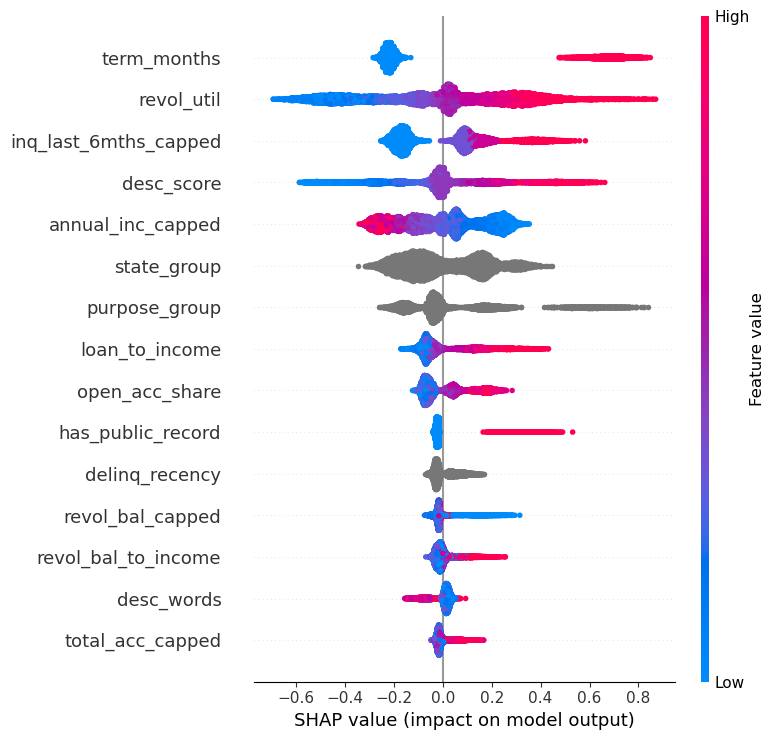

In [32]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_lgb)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

average_impact = np.abs(shap_values).mean(axis=0)
importance = pd.Series(average_impact, index=feature_cols)
importance = importance.sort_values(ascending=False)
print(importance.head(10))

shap.summary_plot(shap_values, X_test_lgb, max_display=15)

# Explain one applicant (the riskiest)

In [33]:
riskiest_position = np.argmax(p_lgb)
riskiest_chance = p_lgb[riskiest_position] * 100
print("Riskiest applicant default chance:", riskiest_chance, "%")

contributions = pd.Series(shap_values[riskiest_position], index=feature_cols)
top_reasons = contributions.sort_values(ascending=False).head(5)

print("Top 5 reasons this applicant is risky:")
print(top_reasons)

print("Their actual values for those features:")
print(X_test_lgb.iloc[riskiest_position][top_reasons.index])

Riskiest applicant default chance: 69.03122777585028 %
Top 5 reasons this applicant is risky:
term_months          0.597286
purpose_group        0.543248
desc_score           0.438424
revol_util           0.353762
has_public_record    0.281944
dtype: float64
Their actual values for those features:
term_months                    60.0
purpose_group        small_business
desc_score                  0.26043
revol_util                     92.2
has_public_record                 1
Name: 10905, dtype: object


In [ ]:
base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_value = float(np.atleast_1d(base_value)[-1])

model_output = final_model.predict(X_test_lgb, raw_score=True)
rebuilt_output = shap_values.sum(axis=1) + base_value
biggest_error = np.abs(model_output - rebuilt_output).max()
print("Biggest error:", biggest_error)